**This notebook generates Figures S3-S4 and creates clean .csv files for related supplementary figures in `field_to_lab.R`.**

Run with

* Python 3.8
* pandas 2.0.3
* matplotlib 3.6.0

In [1]:
# Import standard libraries
import os
import string
from datetime import time

# Import published packages from PyPI
import pandas as pd
import matplotlib.pyplot as plt

**Specify directories**

In [2]:
DATA_IN = 'datasets'
DATA_OUT = 'out'

**Helper functions**

In [3]:
def hrmin_to_hr(hours: int, minutes: int):
    '''Converts a time span in hours and minutes 
        to the number of hours in decimals
    '''
    assert(hours >= 0 and minutes >= 0)
    return hours + minutes / 60

def to_pytime(timestamp):
    ts = timestamp.to_pydatetime()
    return time(hour = ts.hour, minute = ts.minute, second = ts.second)

# Seasonal photoperiods & temperatures at Davy Crockett National Forest (Fig. S3-S4)

## Photoperiods

### Load data

In [4]:
light_df = pd.read_table(os.path.join(
    DATA_IN, 
    'raw',
    'seasonal_field_photoperiod', 
    'ponds5-8_daylight_2001.txt'
))
dark_df = pd.read_table(os.path.join(
    DATA_IN, 
    'raw',
    'seasonal_field_photoperiod', 
    'ponds5-8_darkness_2001.txt'
))

### Data wrangling

In [5]:
photoperiod_df = pd.DataFrame({
    'daylight (hours:minutes)': pd.concat(
        [light_df[col].dropna() for col in light_df.columns], 
        ignore_index = True
    ), 
    'darkness (hours:minutes)': pd.concat(
        [dark_df[col].dropna() for col in dark_df.columns], 
        ignore_index = True
    )
})
photoperiod_df.head()

,daylight (hours:minutes),darkness (hours:minutes)
0,10:09,13:51
1,10:10,13:50
2,10:10,13:50
3,10:11,13:49
4,10:12,13:48


In [6]:
photoperiod_df['daylight (hours)'] = photoperiod_df[
    'daylight (hours:minutes)'
].apply(lambda x: hrmin_to_hr(int(x[0:2]), int(x[3:5])))
photoperiod_df['darkness (hours)'] = photoperiod_df[
    'darkness (hours:minutes)'
].apply(lambda x: hrmin_to_hr(int(x[0:2]), int(x[3:5])))
photoperiod_df.head()

,daylight (hours:minutes),darkness (hours:minutes),daylight (hours),darkness (hours)
0,10:09,13:51,10.150000,13.850000
1,10:10,13:50,10.166667,13.833333
2,10:10,13:50,10.166667,13.833333
3,10:11,13:49,10.183333,13.816667
4,10:12,13:48,10.200000,13.800000


In [7]:
photoperiod_df['doy'] = range(1, photoperiod_df.shape[0] + 1)

In [8]:
photoperiod_df.tail()

,daylight (hours:minutes),darkness (hours:minutes),daylight (hours),darkness (hours),doy
360,10:07,13:53,10.116667,13.883333,361
361,10:07,13:53,10.116667,13.883333,362
362,10:08,13:52,10.133333,13.866667,363
363,10:08,13:52,10.133333,13.866667,364
364,10:09,13:51,10.150000,13.850000,365


### Figure S3

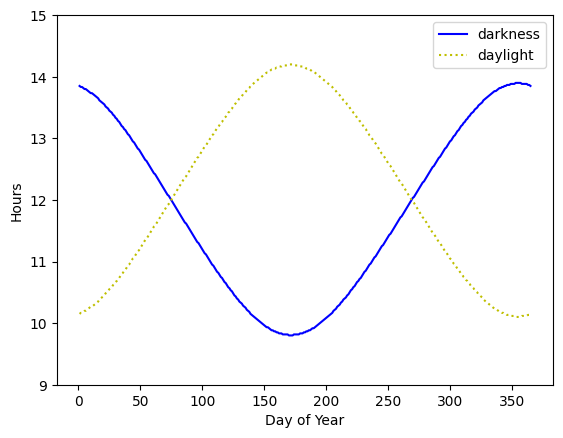

In [9]:
fig, ax = plt.subplots()
ax.plot(
    photoperiod_df['doy'], 
    photoperiod_df['darkness (hours)'], 
    'b', 
    label = 'darkness'
)
ax.plot(
    photoperiod_df['doy'], 
    photoperiod_df['daylight (hours)'], 
    ':y', 
    label = 'daylight'
)
ax.set(xlabel = "Day of Year", ylabel = "Hours", ylim = [9, 15])
plt.legend()
plt.show()
fig.savefig(os.path.join(
    DATA_OUT, 
    'figure_s3.png'
), bbox_inches = 'tight', dpi = 300)

## Air temperatures

### Load data

In [10]:
air_temperature_df = pd.read_csv(
    os.path.join(DATA_IN, 'raw', 'seasonal_field_air_temperature.csv'), 
    index_col = False, 
    parse_dates = ['date']
)

### Figure S4a

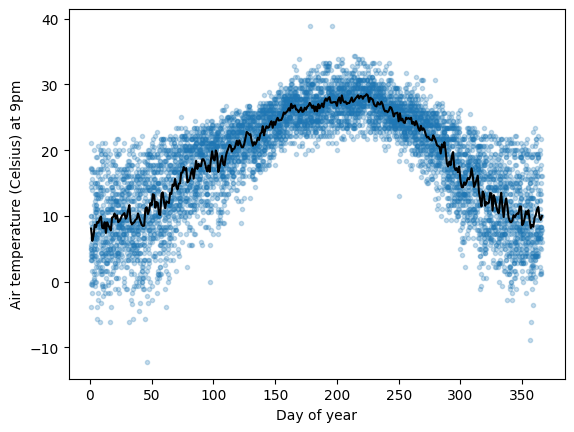

In [11]:
# x is doy, y is count of each doy
fig, ax = plt.subplots()
ax.plot(air_temperature_df['doy'], air_temperature_df[
    'temperature_C'
], '.', alpha = 0.25)
ax.plot(
    list(range(1, 367)), 
    air_temperature_df.filter(items = ['doy', 'temperature_C']).groupby(
        'doy'
    ).mean()['temperature_C'], 
    '-k'
)
ax.set(xlabel = "Day of year", ylabel = "Air temperature (Celsius) at 9pm")
fig.savefig(
    os.path.join(DATA_OUT, 'figure_s4a.png'), 
    bbox_inches = 'tight', 
    dpi = 300
)

### Figure S4b

In [12]:
# variability in temperature between consecutive days across a year
air_temperature_diff1_df = pd.DataFrame()
for year, group in air_temperature_df.filter(
    items = ['year', 'doy', 'temperature_C']
).groupby('year'):
    diff1 = group['temperature_C'].diff()
    mag_diff1 = diff1.abs()
    air_temperature_diff1_df = pd.concat([
        air_temperature_diff1_df, 
        pd.DataFrame({
            'year': [year] * len(diff1),
            'doy_diff1': list(range(1, len(diff1) + 1)), 
            'temp_diff1': diff1, 
            'temp_mag_diff1': mag_diff1
        })
    ])

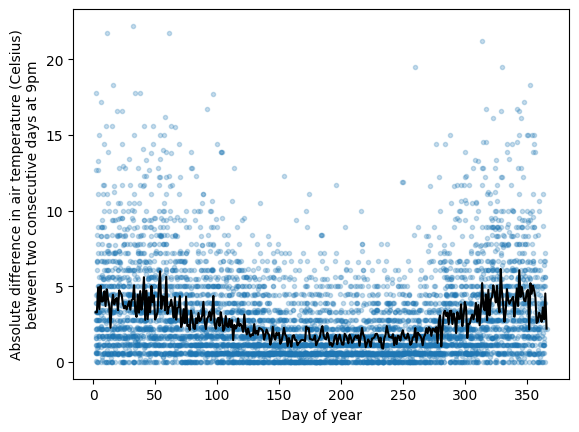

In [13]:
fig, ax = plt.subplots()
ax.plot(
    air_temperature_diff1_df['doy_diff1'], 
    air_temperature_diff1_df['temp_mag_diff1'], 
    '.', 
    alpha = 0.25
)
ax.plot(
    list(range(1, 367)), 
    air_temperature_diff1_df.filter(
        items = ['doy_diff1', 'temp_mag_diff1']
    ).groupby('doy_diff1').mean()['temp_mag_diff1'], 
    '-k'
)
ax.set(
    xlabel = "Day of year", 
    ylabel = "Absolute difference in air temperature (Celsius)\nbetween two consecutive days at 9pm"
)
fig.savefig(
    os.path.join(DATA_OUT, 'figure_s4b.png'), 
    bbox_inches = 'tight', 
    dpi = 300
)

## Pre-process pond water temperature data

### Load & examine data

In [14]:
p1_temperature_df = pd.read_csv(os.path.join(
    DATA_IN, 
    'raw',
    'water_temperatures', 
    'field', 
    '6mo_5min_p1_temperature_HOBO.csv'
), usecols = [1, 2], parse_dates = ['Date-Time (CST/CDT)'])
p4_temperature_df = pd.read_csv(os.path.join(
    DATA_IN, 
    'raw',
    'water_temperatures', 
    'field', 
    '6mo_5min_p4_temperature_HOBO.csv'
), usecols = [1, 2], parse_dates = ['Date-Time (CDT)'])

In [15]:
p1_temperature_df.dtypes

Date-Time (CST/CDT)            datetime64[ns]
Ch: 1 - Temperature   (°C )           float64
dtype: object

In [16]:
p1_temperature_df.head()

,Date-Time (CST/CDT),Ch: 1 - Temperature (°C )
0,2022-06-02 13:19:20,30.03
1,2022-06-02 13:24:20,28.87
2,2022-06-02 13:29:20,27.02
3,2022-06-02 13:34:20,26.77
4,2022-06-02 13:39:20,26.72


In [17]:
p1_temperature_df.isnull().any()

Date-Time (CST/CDT)            False
Ch: 1 - Temperature   (°C )     True
dtype: bool

In [18]:
p4_temperature_df.dtypes

Date-Time (CDT)                datetime64[ns]
Ch: 1 - Temperature   (°C )           float64
dtype: object

In [19]:
p4_temperature_df.head()

,Date-Time (CDT),Ch: 1 - Temperature (°C )
0,2022-06-02 14:09:43,25.65
1,2022-06-02 14:10:09,NaN
2,2022-06-02 14:14:44,30.84
3,2022-06-02 14:19:45,29.94
4,2022-06-02 14:24:46,27.50


In [20]:
p4_temperature_df.isnull().any()

Date-Time (CDT)                False
Ch: 1 - Temperature   (°C )     True
dtype: bool

### Data wrangling

In [21]:
p1_temperature_df['date'] = p1_temperature_df[
    'Date-Time (CST/CDT)'
].apply(func = lambda x: x.to_pydatetime().date())
p1_temperature_df['time'] = p1_temperature_df[
    'Date-Time (CST/CDT)'
].apply(func = lambda x: to_pytime(x))
p1_temperature_df.head()

,Date-Time (CST/CDT),Ch: 1 - Temperature (°C ),date,time
0,2022-06-02 13:19:20,30.03,2022-06-02,13:19:20
1,2022-06-02 13:24:20,28.87,2022-06-02,13:24:20
2,2022-06-02 13:29:20,27.02,2022-06-02,13:29:20
3,2022-06-02 13:34:20,26.77,2022-06-02,13:34:20
4,2022-06-02 13:39:20,26.72,2022-06-02,13:39:20


In [22]:
p4_temperature_df['date'] = p4_temperature_df[
    'Date-Time (CDT)'
].apply(func = lambda x: x.to_pydatetime().date())
p4_temperature_df['time'] = p4_temperature_df[
    'Date-Time (CDT)'
].apply(func = lambda x: to_pytime(x))
p4_temperature_df.head()

,Date-Time (CDT),Ch: 1 - Temperature (°C ),date,time
0,2022-06-02 14:09:43,25.65,2022-06-02,14:09:43
1,2022-06-02 14:10:09,NaN,2022-06-02,14:10:09
2,2022-06-02 14:14:44,30.84,2022-06-02,14:14:44
3,2022-06-02 14:19:45,29.94,2022-06-02,14:19:45
4,2022-06-02 14:24:46,27.50,2022-06-02,14:24:46


**Confirm parsed datetime format**

In [23]:
p1_temperature_df['time'][0]

datetime.time(13, 19, 20)

In [24]:
p1_temperature_df.columns

Index(['Date-Time (CST/CDT)', 'Ch: 1 - Temperature   (°C )', 'date', 'time'], dtype='object')

In [25]:
p4_temperature_df['time'][0]

datetime.time(14, 9, 43)

In [26]:
p4_temperature_df.columns

Index(['Date-Time (CDT)', 'Ch: 1 - Temperature   (°C )', 'date', 'time'], dtype='object')

In [27]:
p4_temperature_df.tail()

,Date-Time (CDT),Ch: 1 - Temperature (°C ),date,time
26112,2022-09-01 12:54:49,26.47,2022-09-01,12:54:49
26113,2022-09-01 12:59:50,26.47,2022-09-01,12:59:50
26114,2022-09-01 13:01:41,NaN,2022-09-01,13:01:41
26115,2022-09-01 13:01:42,NaN,2022-09-01,13:01:42
26116,2022-09-01 13:01:54,NaN,2022-09-01,13:01:54


**Rename column for temperature**

In [28]:
p1_temperature_df.rename(
    columns = {"Ch: 1 - Temperature   (°C )": "temperature_C"}, 
    inplace = True
)
p1_temperature_df.head()

,Date-Time (CST/CDT),temperature_C,date,time
0,2022-06-02 13:19:20,30.03,2022-06-02,13:19:20
1,2022-06-02 13:24:20,28.87,2022-06-02,13:24:20
2,2022-06-02 13:29:20,27.02,2022-06-02,13:29:20
3,2022-06-02 13:34:20,26.77,2022-06-02,13:34:20
4,2022-06-02 13:39:20,26.72,2022-06-02,13:39:20


In [29]:
p4_temperature_df.rename(
    columns = {"Ch: 1 - Temperature   (°C )": "temperature_C"}, 
    inplace = True
)
p4_temperature_df.head()

,Date-Time (CDT),temperature_C,date,time
0,2022-06-02 14:09:43,25.65,2022-06-02,14:09:43
1,2022-06-02 14:10:09,NaN,2022-06-02,14:10:09
2,2022-06-02 14:14:44,30.84,2022-06-02,14:14:44
3,2022-06-02 14:19:45,29.94,2022-06-02,14:19:45
4,2022-06-02 14:24:46,27.50,2022-06-02,14:24:46


### Write to .csv files for analysis in R

In [30]:
p1_temperature_df.to_csv(
    os.path.join(DATA_IN, "processed", "pond_water_temperature_p1_HOBO.csv"),
    index = False
)
p4_temperature_df.to_csv(
    os.path.join(DATA_IN, "processed", "pond_water_temperature_p4_HOBO.csv"),
    index = False
)

# Merge chamber water temperature .csv files

In [31]:
dfs_list = list()
tank_labels = string.ascii_lowercase
i = 0

for entry in os.scandir(os.path.join(
    DATA_IN, 
    'raw',
    'water_temperatures', 
    'chamber'
)):
    if entry.name.endswith('.csv') and entry.is_file():
        df = pd.read_csv(
            os.path.join(
                DATA_IN, 
                'raw',
                'water_temperatures', 
                'chamber', 
                entry.name
            ),
            usecols = [1, 2], 
            parse_dates = [0]
        )
        df['room'] = entry.name[0:4]
        if entry.name[0:4] == '210F':
            df['season'] = 'spring_fall'
        elif entry.name[0:4] == '227A':
            df['season'] = 'summer'
        elif entry.name[0:4] == '227B':
            df['season'] = 'winter'
        df['datetime'] = df.iloc[:, 0]
        df['date'] = df.iloc[:, 0].apply(
            func = lambda x: x.to_pydatetime().date()
        )
        df['time'] = df.iloc[:, 0].apply(
            func = lambda x: to_pytime(x)
        )
        df['tank'] = tank_labels[i]
        df.rename(
            columns = { df.columns[1]: "temperature_C" }, 
            inplace = True
        )
        dfs_list.append(df.iloc[:, 1:])
        i += 1

In [32]:
pd.concat(dfs_list, ignore_index = True).to_csv(os.path.join(
    DATA_IN,
    "processed",
    "chamber_water_temperature_HOBO.csv"
), index = False)